In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

# Load the dataset
housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

print("Dataset shape:", X.shape)
print("Predictor variables:", X.columns.tolist())

display(X.head())


Matplotlib is building the font cache; this may take a moment.


Dataset shape: (20640, 8)
Predictor variables: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [4]:

X_train_pool, X_test, y_train_pool, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training pool:", len(X_train_pool))
print("Test set:", len(X_test))


Training pool: 16512
Test set: 4128


In [5]:

# Select 500 observations for training
X_sample = X_train_pool.sample(n=500, random_state=42)
y_sample = y_train_pool.loc[X_sample.index]

# Create and train the linear regression model
linear_model = LinearRegression()
linear_model.fit(X_sample, y_sample)

# Predict house values using the fixed test set
y_pred = linear_model.predict(X_test)

# Calculate test Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

print("Training size:", len(X_sample))
print("Test MSE:", mse)


Training size: 500
Test MSE: 0.8966073381961995


In [6]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create degree-2 polynomial regression model
poly_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train using the SAME 500 observations
poly_model.fit(X_sample, y_sample)

# Predict using the SAME test set
y_poly_pred = poly_model.predict(X_test)

# Calculate polynomial regression test MSE
poly_mse = mean_squared_error(y_test, y_poly_pred)

print("Linear Regression MSE:", mse)
print("Polynomial Regression MSE:", poly_mse)


Linear Regression MSE: 0.8966073381961995
Polynomial Regression MSE: 161.5692052811834


In [7]:

# Different training-set sizes
train_sizes = [50, 100, 250, 500, 1000, 2500, 5000]

linear_mse = []
poly_mse_list = []

for size in train_sizes:

    # Randomly select training observations
    X_subset = X_train_pool.sample(n=size, random_state=42)
    y_subset = y_train_pool.loc[X_subset.index]

    # Linear regression
    linear = LinearRegression()
    linear.fit(X_subset, y_subset)

    linear_pred = linear.predict(X_test)
    linear_mse.append(mean_squared_error(y_test, linear_pred))

    # Polynomial regression
    poly = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    )

    poly.fit(X_subset, y_subset)

    poly_pred = poly.predict(X_test)
    poly_mse_list.append(mean_squared_error(y_test, poly_pred))

# Display results
results = pd.DataFrame({
    "Training Size": train_sizes,
    "Linear MSE": linear_mse,
    "Polynomial MSE": poly_mse_list
})

display(results)


,Training Size,Linear MSE,Polynomial MSE
0,50,0.783552,591154.885124
1,100,0.759283,858.197216
2,250,0.861865,447.276565
3,500,0.896607,161.569205
4,1000,0.749870,29.373829
5,2500,0.574151,0.770155
6,5000,0.548813,0.494802


In [8]:

train_sizes = [50, 100, 250, 500, 1000, 2500, 5000]
n_trials = 20

trial_results = []

for size in train_sizes:
    for trial in range(n_trials):

        # Select a different random sample each trial
        X_subset = X_train_pool.sample(
            n=size, random_state=trial
        )
        y_subset = y_train_pool.loc[X_subset.index]

        # Linear regression
        linear = LinearRegression()
        linear.fit(X_subset, y_subset)

        linear_pred = linear.predict(X_test)
        linear_error = mean_squared_error(y_test, linear_pred)

        # Polynomial regression
        poly = make_pipeline(
            StandardScaler(),
            PolynomialFeatures(degree=2, include_bias=False),
            LinearRegression()
        )

        poly.fit(X_subset, y_subset)

        poly_pred = poly.predict(X_test)
        poly_error = mean_squared_error(y_test, poly_pred)

        trial_results.append({
            "Training Size": size,
            "Trial": trial,
            "Linear MSE": linear_error,
            "Polynomial MSE": poly_error
        })

trial_df = pd.DataFrame(trial_results)

# Calculate mean and standard deviation
summary = trial_df.groupby("Training Size").agg({
    "Linear MSE": ["mean", "std"],
    "Polynomial MSE": ["mean", "std"]
})

display(summary)


Linear MSE           Polynomial MSE               
                    mean       std           mean            std
Training Size                                                   
50              1.219294  0.547571  224711.772648  367629.305556
100             0.930597  0.281067    5734.560164   10526.399369
250             0.790927  0.169810    1024.376529    2480.579410
500             0.694760  0.122689     112.528217     123.698715
1000            0.632283  0.084608      65.803001     106.236023
2500            0.595037  0.042082       9.581632      12.950956
5000            0.578209  0.039312       2.883753       3.985924

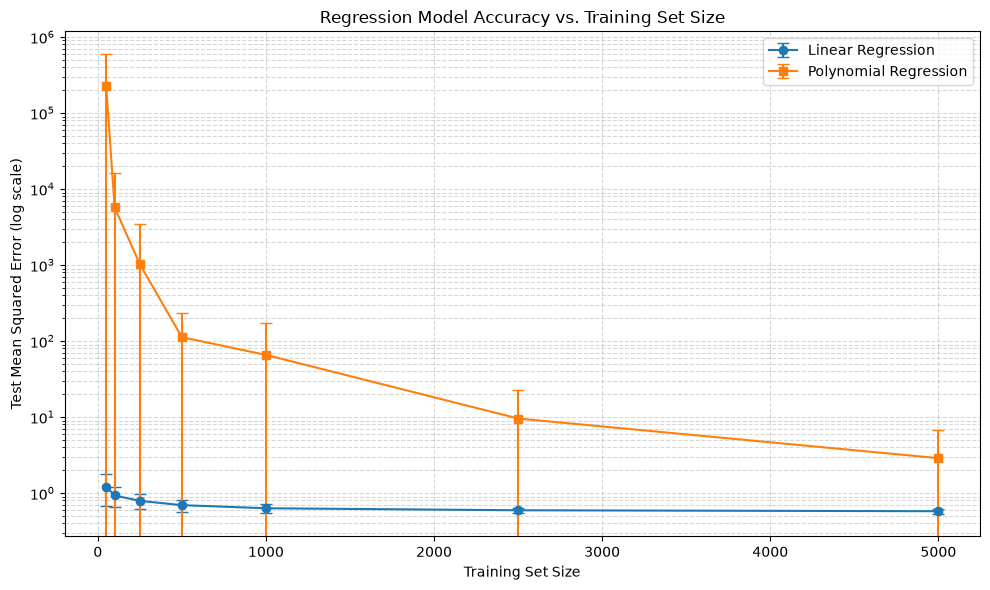

In [9]:

plt.figure(figsize=(10, 6))

# Linear regression results
plt.errorbar(
    train_sizes,
    summary["Linear MSE"]["mean"],
    yerr=summary["Linear MSE"]["std"],
    marker="o",
    capsize=4,
    label="Linear Regression"
)

# Polynomial regression results
plt.errorbar(
    train_sizes,
    summary["Polynomial MSE"]["mean"],
    yerr=summary["Polynomial MSE"]["std"],
    marker="s",
    capsize=4,
    label="Polynomial Regression"
)

plt.yscale("log")

plt.xlabel("Training Set Size")
plt.ylabel("Test Mean Squared Error (log scale)")
plt.title("Regression Model Accuracy vs. Training Set Size")

plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [10]:

from sklearn.preprocessing import StandardScaler

coefficient_results = []

for size in train_sizes:
    coefficients = []

    for trial in range(n_trials):

        X_subset = X_train_pool.sample(
            n=size, random_state=trial
        )
        y_subset = y_train_pool.loc[X_subset.index]

        # Standardize predictors for comparable coefficients
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_subset)

        # Train linear regression
        model = LinearRegression()
        model.fit(X_scaled, y_subset)

        coefficients.append(model.coef_)

    # Standard deviation of each coefficient across trials
    coef_std = np.std(coefficients, axis=0, ddof=1)

    coefficient_results.append({
        "Training Size": size,
        "Mean Coefficient Std": np.mean(coef_std)
    })

coef_df = pd.DataFrame(coefficient_results)

display(coef_df)


,Training Size,Mean Coefficient Std
0,50,0.211341
1,100,0.155082
2,250,0.104154
3,500,0.078171
4,1000,0.072927
5,2500,0.051169
6,5000,0.036519


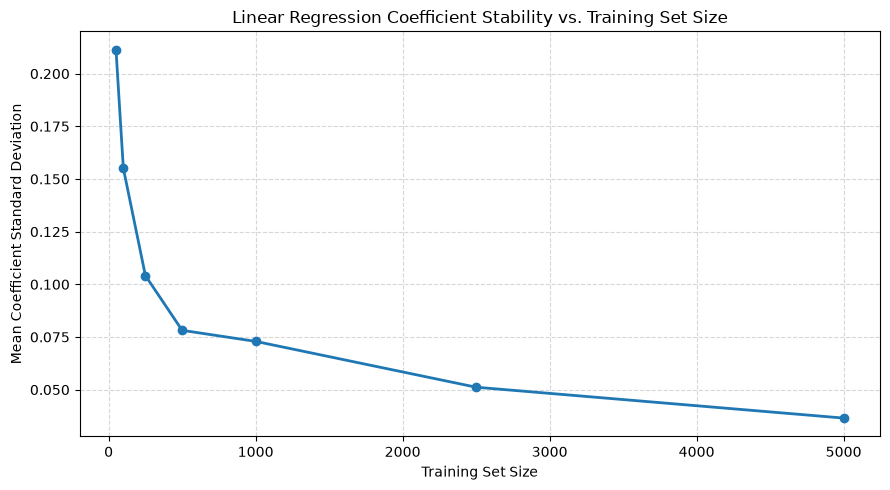

In [11]:

plt.figure(figsize=(9, 5))

plt.plot(
    coef_df["Training Size"],
    coef_df["Mean Coefficient Std"],
    marker="o",
    linewidth=2
)

plt.xlabel("Training Set Size")
plt.ylabel("Mean Coefficient Standard Deviation")
plt.title("Linear Regression Coefficient Stability vs. Training Set Size")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [12]:

poly_coef_results = []

for size in train_sizes:
    coefficients = []

    for trial in range(n_trials):

        X_subset = X_train_pool.sample(
            n=size, random_state=trial
        )
        y_subset = y_train_pool.loc[X_subset.index]

        # Standardize predictors
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_subset)

        # Generate polynomial features
        poly_features = PolynomialFeatures(
            degree=2, include_bias=False
        )
        X_poly = poly_features.fit_transform(X_scaled)

        # Train polynomial regression
        model = LinearRegression()
        model.fit(X_poly, y_subset)

        coefficients.append(model.coef_)

    # Calculate coefficient variability across trials
    coef_std = np.std(coefficients, axis=0, ddof=1)

    poly_coef_results.append({
        "Training Size": size,
        "Mean Coefficient Std": np.mean(coef_std)
    })

poly_coef_df = pd.DataFrame(poly_coef_results)

display(poly_coef_df)


,Training Size,Mean Coefficient Std
0,50,11.009452
1,100,1.724742
2,250,0.856122
3,500,0.729235
4,1000,0.616070
5,2500,0.309174
6,5000,0.187753


In [13]:

# Fit the scaler once using the training pool only
fixed_scaler = StandardScaler().fit(X_train_pool)

X_pool_scaled = pd.DataFrame(
    fixed_scaler.transform(X_train_pool),
    index=X_train_pool.index,
    columns=X_train_pool.columns
)

# Create polynomial features using the fixed scaling
poly_transform = PolynomialFeatures(
    degree=2, include_bias=False
)

X_pool_poly = poly_transform.fit_transform(X_pool_scaled)

corrected_results = []

for size in train_sizes:
    linear_coefs = []
    poly_coefs = []

    for trial in range(n_trials):
        indices = X_train_pool.sample(
            n=size, random_state=trial
        ).index

        y_subset = y_train_pool.loc[indices]

        # Linear regression
        linear = LinearRegression()
        linear.fit(X_pool_scaled.loc[indices], y_subset)
        linear_coefs.append(linear.coef_)

        # Polynomial regression
        positions = X_train_pool.index.get_indexer(indices)

        poly = LinearRegression()
        poly.fit(X_pool_poly[positions], y_subset)
        poly_coefs.append(poly.coef_)

    corrected_results.append({
        "Training Size": size,
        "Linear Coefficient Std": np.std(
            linear_coefs, axis=0, ddof=1
        ).mean(),
        "Polynomial Coefficient Std": np.std(
            poly_coefs, axis=0, ddof=1
        ).mean()
    })

corrected_df = pd.DataFrame(corrected_results)

display(corrected_df)


,Training Size,Linear Coefficient Std,Polynomial Coefficient Std
0,50,0.480729,8.558634
1,100,0.410416,1.843273
2,250,0.278754,0.959695
3,500,0.263463,0.591746
4,1000,0.233417,0.455560
5,2500,0.192675,0.289964
6,5000,0.170937,0.229698


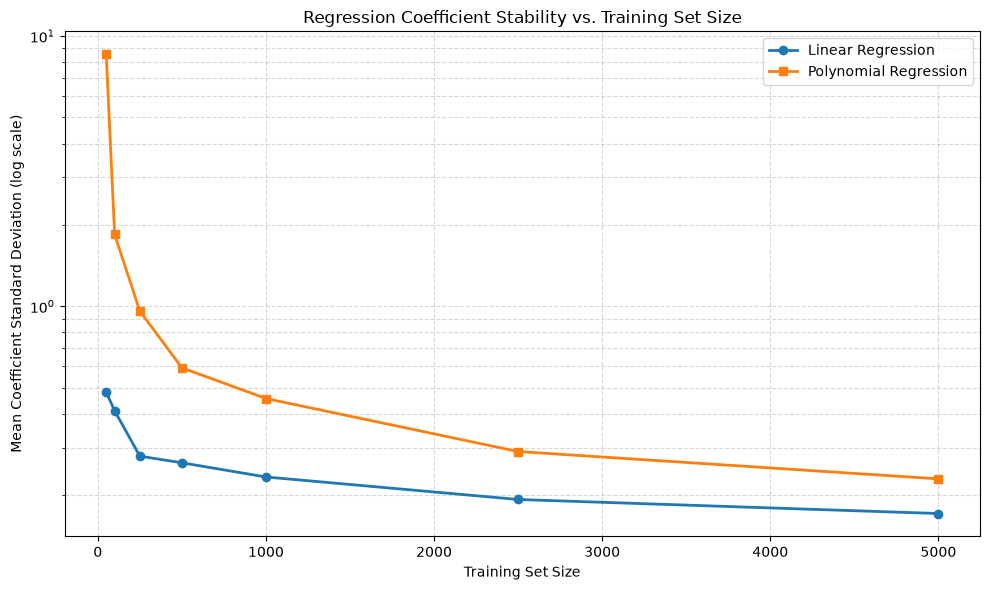

In [14]:

plt.figure(figsize=(10, 6))

plt.plot(
    corrected_df["Training Size"],
    corrected_df["Linear Coefficient Std"],
    marker="o",
    linewidth=2,
    label="Linear Regression"
)

plt.plot(
    corrected_df["Training Size"],
    corrected_df["Polynomial Coefficient Std"],
    marker="s",
    linewidth=2,
    label="Polynomial Regression"
)

# Log scale makes both models visible
plt.yscale("log")

plt.xlabel("Training Set Size")
plt.ylabel("Mean Coefficient Standard Deviation (log scale)")
plt.title("Regression Coefficient Stability vs. Training Set Size")

plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()

# Save graph for final report
plt.savefig("coefficient_stability.png", dpi=300, bbox_inches="tight")

plt.show()


In [15]:

# Select 2,500 training observations
X_subset = X_train_pool.sample(n=2500, random_state=42)
y_subset = y_train_pool.loc[X_subset.index]

# Generate reproducible Gaussian noise
rng = np.random.default_rng(42)

# Noise standard deviation = 20% of target std
noise_std = 0.20 * y_subset.std()

noise = rng.normal(
    loc=0,
    scale=noise_std,
    size=len(y_subset)
)

# Create noisy training targets
y_noisy = y_subset + noise

print("Original target std:", y_subset.std())
print("Noise std:", noise_std)
print("First five original targets:")
print(y_subset.head().values)

print("First five noisy targets:")
print(y_noisy.head().values)


Original target std: 1.1759684905630547
Noise std: 0.23519369811261095
First five original targets:
[0.967   0.755   4.309   3.326   5.00001]
First five noisy targets:
[1.03866754 0.51040229 4.48550139 3.54721489 4.54113882]


In [16]:

# Define models
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Polynomial Regression": make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    )
}

robustness_results = []

for name, model in models.items():

    # Train on clean data
    model.fit(X_subset, y_subset)
    clean_pred = model.predict(X_test)
    clean_mse = mean_squared_error(y_test, clean_pred)

    # Train on noisy data
    model.fit(X_subset, y_noisy)
    noisy_pred = model.predict(X_test)
    noisy_mse = mean_squared_error(y_test, noisy_pred)

    robustness_results.append({
        "Model": name,
        "Clean MSE": clean_mse,
        "Noisy MSE": noisy_mse,
        "MSE Change": noisy_mse - clean_mse
    })

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df)


,Model,Clean MSE,Noisy MSE,MSE Change
0,Linear Regression,0.574151,0.572433,-0.001718
1,Polynomial Regression,0.770155,0.709400,-0.060755


In [17]:

from sklearn.base import clone

noise_levels = [0.0, 0.1, 0.2, 0.4]
n_noise_trials = 20

noise_results = []

for noise_level in noise_levels:
    for trial in range(n_noise_trials):

        # Create reproducible noise
        rng = np.random.default_rng(trial)

        noise = rng.normal(
            0,
            noise_level * y_subset.std(),
            size=len(y_subset)
        )

        y_train_noisy = y_subset + noise

        for name, model in models.items():

            # Train a fresh model
            current_model = clone(model)
            current_model.fit(X_subset, y_train_noisy)

            predictions = current_model.predict(X_test)
            test_mse = mean_squared_error(y_test, predictions)

            noise_results.append({
                "Noise Level": noise_level,
                "Trial": trial,
                "Model": name,
                "Test MSE": test_mse
            })

noise_df = pd.DataFrame(noise_results)

noise_summary = noise_df.groupby(
    ["Model", "Noise Level"]
)["Test MSE"].agg(["mean", "std"])

display(noise_summary)


mean       std
Model                 Noise Level                    
Linear Regression     0.0          0.574151  0.000000
                      0.1          0.573943  0.001772
                      0.2          0.573853  0.003511
                      0.4          0.574025  0.006898
Polynomial Regression 0.0          0.770155  0.000000
                      0.1          0.785759  0.072576
                      0.2          0.812735  0.151763
                      0.4          0.900804  0.335954

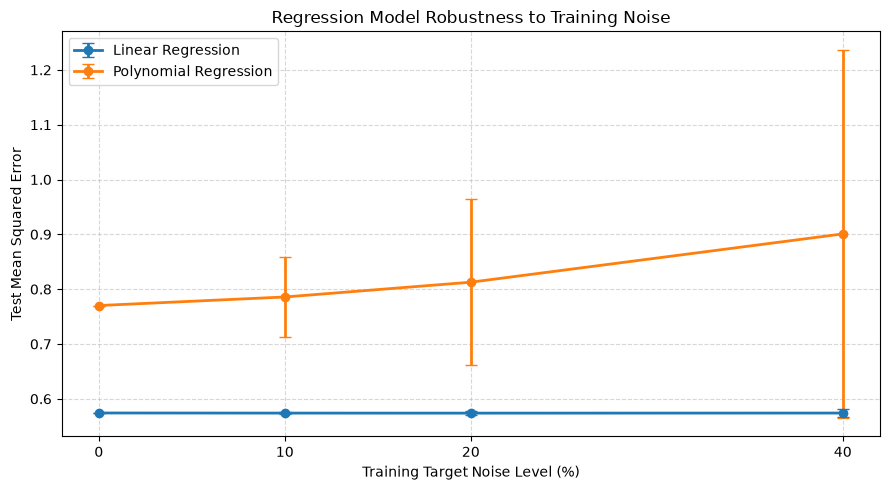

In [18]:

plt.figure(figsize=(9, 5))

for model_name in noise_df["Model"].unique():

    model_summary = noise_summary.loc[model_name]

    plt.errorbar(
        model_summary.index * 100,
        model_summary["mean"],
        yerr=model_summary["std"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=model_name
    )

plt.xlabel("Training Target Noise Level (%)")
plt.ylabel("Test Mean Squared Error")
plt.title("Regression Model Robustness to Training Noise")

plt.xticks([0, 10, 20, 40])
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "noise_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [19]:

overfit_results = []

for size in train_sizes:
    for trial in range(n_trials):

        # Select training observations
        X_subset = X_train_pool.sample(
            n=size, random_state=trial
        )
        y_subset_trial = y_train_pool.loc[X_subset.index]

        # Define models
        current_models = {
            "Linear Regression": make_pipeline(
                StandardScaler(),
                LinearRegression()
            ),
            "Polynomial Regression": make_pipeline(
                StandardScaler(),
                PolynomialFeatures(
                    degree=2,
                    include_bias=False
                ),
                LinearRegression()
            )
        }

        for name, model in current_models.items():

            # Train model
            model.fit(X_subset, y_subset_trial)

            # Training predictions
            train_pred = model.predict(X_subset)
            train_mse = mean_squared_error(
                y_subset_trial, train_pred
            )

            # Test predictions
            test_pred = model.predict(X_test)
            test_mse = mean_squared_error(
                y_test, test_pred
            )

            overfit_results.append({
                "Training Size": size,
                "Trial": trial,
                "Model": name,
                "Training MSE": train_mse,
                "Test MSE": test_mse
            })

overfit_df = pd.DataFrame(overfit_results)

overfit_summary = overfit_df.groupby(
    ["Model", "Training Size"]
)[["Training MSE", "Test MSE"]].mean()

display(overfit_summary)


Training MSE       Test MSE
Model                 Training Size                             
Linear Regression     50                 0.344052       1.219294
                      100                0.381579       0.930597
                      250                0.433262       0.790927
                      500                0.458793       0.694760
                      1000               0.470569       0.632283
                      2500               0.487808       0.595037
                      5000               0.498967       0.578209
Polynomial Regression 50                 0.032149  224711.772648
                      100                0.174375    5734.560164
                      250                0.273294    1024.376529
                      500                0.321580     112.528217
                      1000               0.349075      65.803001
                      2500               0.378595       9.581632
                      5000               0.397086       2.883753

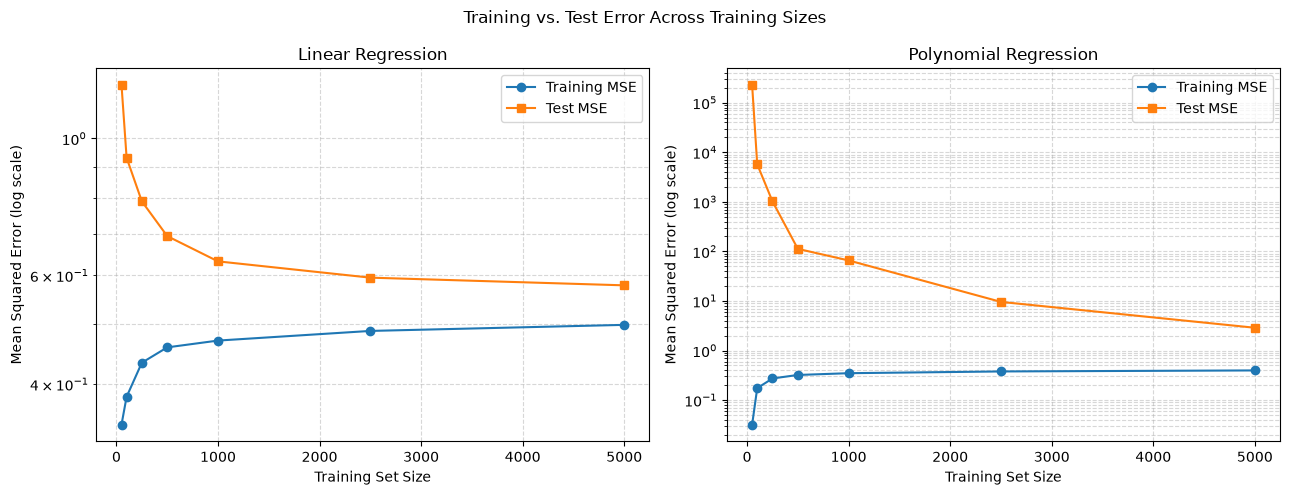

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

model_names = [
    "Linear Regression",
    "Polynomial Regression"
]

for ax, model_name in zip(axes, model_names):

    model_data = overfit_summary.loc[model_name]

    ax.plot(
        model_data.index,
        model_data["Training MSE"],
        marker="o",
        label="Training MSE"
    )

    ax.plot(
        model_data.index,
        model_data["Test MSE"],
        marker="s",
        label="Test MSE"
    )

    ax.set_yscale("log")
    ax.set_xlabel("Training Set Size")
    ax.set_ylabel("Mean Squared Error (log scale)")
    ax.set_title(model_name)

    ax.legend()
    ax.grid(True, which="both", linestyle="--", alpha=0.5)

plt.suptitle("Training vs. Test Error Across Training Sizes")
plt.tight_layout()

plt.savefig(
    "training_vs_test_mse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [21]:

from sklearn.linear_model import Ridge

ridge_results = []

for size in train_sizes:
    for trial in range(n_trials):

        X_subset = X_train_pool.sample(
            n=size, random_state=trial
        )
        y_subset_trial = y_train_pool.loc[X_subset.index]

        models_ridge = {
            "Linear": make_pipeline(
                StandardScaler(),
                LinearRegression()
            ),
            "Polynomial": make_pipeline(
                StandardScaler(),
                PolynomialFeatures(
                    degree=2,
                    include_bias=False
                ),
                LinearRegression()
            ),
            "Polynomial Ridge": make_pipeline(
                StandardScaler(),
                PolynomialFeatures(
                    degree=2,
                    include_bias=False
                ),
                StandardScaler(),
                Ridge(alpha=100)
            )
        }

        for name, model in models_ridge.items():

            model.fit(X_subset, y_subset_trial)
            predictions = model.predict(X_test)

            ridge_results.append({
                "Training Size": size,
                "Trial": trial,
                "Model": name,
                "Test MSE": mean_squared_error(
                    y_test, predictions
                )
            })

ridge_df = pd.DataFrame(ridge_results)

ridge_summary = ridge_df.groupby(
    ["Model", "Training Size"]
)["Test MSE"].agg(["mean", "std"])

display(ridge_summary)


mean            std
Model            Training Size                              
Linear           50                  1.219294       0.547571
                 100                 0.930597       0.281067
                 250                 0.790927       0.169810
                 500                 0.694760       0.122689
                 1000                0.632283       0.084608
                 2500                0.595037       0.042082
                 5000                0.578209       0.039312
Polynomial       50             224711.772648  367629.305556
                 100              5734.560164   10526.399369
                 250              1024.376529    2480.579410
                 500               112.528217     123.698715
                 1000               65.803001     106.236023
                 2500                9.581632      12.950956
                 5000                2.883753       3.985924
Polynomial Ridge 50                365.958588    1001.193246
                 100               621.408608    1758.792665
                 250                93.642622     169.898172
                 500                23.043216      40.623072
                 1000               19.850495      48.421045
                 2500                6.669588       8.167047
                 5000                2.561792       3.769175

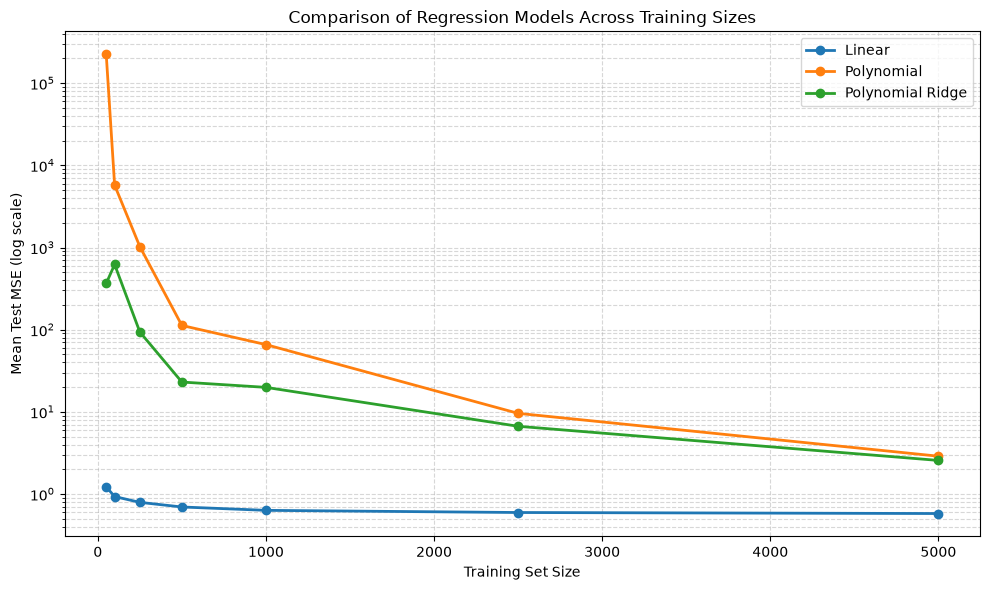

In [22]:

plt.figure(figsize=(10, 6))

for name in ["Linear", "Polynomial", "Polynomial Ridge"]:

    model_data = ridge_summary.loc[name]

    plt.plot(
        model_data.index,
        model_data["mean"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.yscale("log")

plt.xlabel("Training Set Size")
plt.ylabel("Mean Test MSE (log scale)")
plt.title("Comparison of Regression Models Across Training Sizes")

plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "ridge_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [23]:

# Select 5,000 training observations
X_diag = X_train_pool.sample(n=5000, random_state=0)
y_diag = y_train_pool.loc[X_diag.index]

# Train polynomial regression
poly_diag = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_diag.fit(X_diag, y_diag)

# Predict on the test set
predictions = poly_diag.predict(X_test)

# Calculate squared prediction errors
squared_errors = (y_test.to_numpy() - predictions) ** 2

print("Test MSE:", np.mean(squared_errors))
print("Median squared error:", np.median(squared_errors))
print("Largest squared error:", np.max(squared_errors))

# Percentage of total squared error from worst 1%
n_top = max(1, int(len(squared_errors) * 0.01))

top_errors = np.sort(squared_errors)[-n_top:]

percentage = (
    np.sum(top_errors) / np.sum(squared_errors)
) * 100

print("Error contributed by worst 1%:", percentage, "%")


Test MSE: 6.398655187942405
Median squared error: 0.10783005713774493
Largest squared error: 17210.915107681343
Error contributed by worst 1%: 94.96691693277938 %
